<center><h1>Kim_Beomjun_HW7</h1></center>

Name: Beomjun Kim 
<br>
Github Username: valen991693
<br>
USC ID: 4391-4935-38

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import accuracy_score, calinski_harabasz_score

from sklearn.cluster import KMeans

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

### (a) Download the Anuran Calls (MFCCs) Data Set

In [ ]:
df = pd.read_csv("../data/Frogs_MFCCs.csv")

X = df.iloc[:, :22]
y = df[["Family", "Genus", "Species"]]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42
)

print("Dataset shape:", df.shape)
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("\nLabels:")
print(y.nunique())

Dataset shape: (7195, 26)
Training set: (5036, 22)
Test set: (2159, 22)

Labels:
Family      4
Genus       8
Species    10
dtype: int64


### (b) Train a classifier for each label

#### (i) Research

**Exact Match Ratio (Subset Accuracy)**

Exact match ratio measures the proportion of samples for which all predicted labels exactly match the corresponding true labels.

$$
\text{Exact Match Ratio} = \frac{1}{N}\sum_{i=1}^{N}\mathbb{1}(y_i=\hat{y}_i)
$$

A prediction is considered correct only when all three labels (Family, Genus, and Species) are predicted correctly.

**Hamming Loss**

Hamming loss measures the proportion of incorrectly predicted labels across all samples and label dimensions.

$$
\text{Hamming Loss} = \frac{1}{NL}\sum_{i=1}^{N}\sum_{j=1}^{L}\mathbb{1}(y_{ij}\neq\hat{y}_{ij})
$$

where $N$ is the number of samples and $L=3$ is the number of label dimensions.

A lower Hamming loss indicates better classification performance.

**Hamming Score**

For this multi-output classification problem, Hamming score is defined as the proportion of correctly predicted label values.

$$
\text{Hamming Score} = 1-\text{Hamming Loss}
$$

A higher Hamming score indicates better classification performance.

Unlike exact match ratio, Hamming score gives partial credit when only some of the labels are predicted correctly.

#### (ii) Train a SVM for each of the labels

In [3]:
labels = ["Family", "Genus", "Species"]

param_grid = {
    "estimator__C": np.logspace(-2, 3, 6),
    "estimator__gamma": np.logspace(-3, 2, 6)
}

rbf_predictions = pd.DataFrame(index=y_test.index)
rbf_results = {}

for label in labels:
    model = OneVsRestClassifier(
        SVC(kernel="rbf")
    )

    grid = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        cv=10,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X_train, y_train[label])

    rbf_predictions[label] = grid.predict(X_test)

    rbf_results[label] = {
        "Best C": grid.best_params_["estimator__C"],
        "Best Gamma": grid.best_params_["estimator__gamma"],
        "CV Accuracy": grid.best_score_,
        "Test Accuracy": accuracy_score(
            y_test[label],
            rbf_predictions[label]
        )
    }

rbf_results_df = pd.DataFrame(rbf_results).T

print("RBF SVM Results:")
display(rbf_results_df)

print("\nExact Match Ratio:",
      (y_test == rbf_predictions).all(axis=1).mean())

print("Hamming Loss:",
      (y_test != rbf_predictions).to_numpy().mean())

print("Hamming Score:",
      (y_test == rbf_predictions).to_numpy().mean())

RBF SVM Results:


,Best C,Best Gamma,CV Accuracy,Test Accuracy
Family,100.0,1.0,0.992058,0.995831
Genus,10.0,1.0,0.990070,0.990273
Species,10.0,1.0,0.989871,0.990736



Exact Match Ratio: 0.9874942102825383
Hamming Loss: 0.0077196232823838196
Hamming Score: 0.9922803767176162


#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [4]:
param_grid_l1 = {
    "classifier__estimator__C": np.logspace(-3, 3, 7)
}

l1_predictions = pd.DataFrame(index=y_test.index)
l1_results = {}

for label in labels:
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", OneVsRestClassifier(
            LinearSVC(
                penalty="l1",
                dual=False,
                max_iter=50000,
                random_state=42
            )
        ))
    ])

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid_l1,
        cv=10,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X_train, y_train[label])

    l1_predictions[label] = grid.predict(X_test)

    l1_results[label] = {
        "Best C": grid.best_params_["classifier__estimator__C"],
        "CV Accuracy": grid.best_score_,
        "Test Accuracy": accuracy_score(
            y_test[label],
            l1_predictions[label]
        )
    }

l1_results_df = pd.DataFrame(l1_results).T

print("L1-Penalized SVM Results:")
display(l1_results_df)

print("\nExact Match Ratio:",
      (y_test == l1_predictions).all(axis=1).mean())

print("Hamming Loss:",
      (y_test != l1_predictions).to_numpy().mean())

print("Hamming Score:",
      (y_test == l1_predictions).to_numpy().mean())

L1-Penalized SVM Results:


,Best C,CV Accuracy,Test Accuracy
Family,1.0,0.940629,0.928671
Genus,10.0,0.952742,0.941640
Species,10.0,0.960285,0.959240



Exact Match Ratio: 0.9129226493747105
Hamming Loss: 0.05681642735834491
Hamming Score: 0.9431835726416551


#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [5]:
param_grid_smote = {
    "classifier__estimator__C": np.logspace(-3, 3, 7)
}

smote_predictions = pd.DataFrame(index=y_test.index)
smote_results = {}

for label in labels:
    pipeline = ImbPipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(
            random_state=42,
            k_neighbors=3
        )),
        ("classifier", OneVsRestClassifier(
            LinearSVC(
                penalty="l1",
                dual=False,
                max_iter=50000,
                random_state=42
            )
        ))
    ])

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid_smote,
        cv=10,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X_train, y_train[label])

    smote_predictions[label] = grid.predict(X_test)

    smote_results[label] = {
        "Best C": grid.best_params_["classifier__estimator__C"],
        "CV Accuracy": grid.best_score_,
        "Test Accuracy": accuracy_score(
            y_test[label],
            smote_predictions[label]
        )
    }

smote_results_df = pd.DataFrame(smote_results).T

print("SMOTE + L1-Penalized SVM Results:")
display(smote_results_df)

print("\nExact Match Ratio:",
      (y_test == smote_predictions).all(axis=1).mean())

print("Hamming Loss:",
      (y_test != smote_predictions).to_numpy().mean())

print("Hamming Score:",
      (y_test == smote_predictions).to_numpy().mean())

SMOTE + L1-Penalized SVM Results:


,Best C,CV Accuracy,Test Accuracy
Family,100.0,0.920971,0.906901
Genus,1.0,0.910250,0.902270
Species,0.1,0.955718,0.961556



Exact Match Ratio: 0.8522464103751737
Hamming Loss: 0.07642427049559981
Hamming Score: 0.9235757295044001


In [6]:
comparison = pd.DataFrame({
    "Model": [
        "RBF SVM",
        "L1-Penalized SVM",
        "SMOTE + L1-Penalized SVM"
    ],
    "Exact Match Ratio": [
        (y_test == rbf_predictions).all(axis=1).mean(),
        (y_test == l1_predictions).all(axis=1).mean(),
        (y_test == smote_predictions).all(axis=1).mean()
    ],
    "Hamming Loss": [
        (y_test != rbf_predictions).to_numpy().mean(),
        (y_test != l1_predictions).to_numpy().mean(),
        (y_test != smote_predictions).to_numpy().mean()
    ]
})

comparison["Hamming Score"] = 1 - comparison["Hamming Loss"]

display(comparison)

,Model,Exact Match Ratio,Hamming Loss,Hamming Score
0,RBF SVM,0.987494,0.007720,0.992280
1,L1-Penalized SVM,0.912923,0.056816,0.943184
2,SMOTE + L1-Penalized SVM,0.852246,0.076424,0.923576


##### Classification Results and Conclusions

The RBF SVM achieved the best overall performance, with an exact match ratio of 0.9875, a Hamming loss of 0.0077, and a Hamming score of 0.9923.

The L1-penalized SVM achieved an exact match ratio of 0.9129 and a Hamming loss of 0.0568, indicating lower predictive performance than the RBF SVM.

After applying SMOTE, the exact match ratio decreased to 0.8522, while the Hamming loss increased to 0.0764. Although SMOTE addresses class imbalance, it did not improve overall classification performance in this experiment. However, the Species test accuracy increased slightly from 0.9592 to 0.9616.

Overall, the RBF SVM performed best among the three approaches, suggesting that its nonlinear decision boundaries were more effective for this dataset. Additional class-level evaluation would be needed to determine whether SMOTE improved predictions for minority classes.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

In [7]:
X_cluster = df.iloc[:, :22].to_numpy()

k_values = range(2, 51)
n_simulations = 50
simulation_results = []

for seed in range(n_simulations):
    ch_scores = []
    cluster_labels_list = []

    for k in k_values:
        model = KMeans(
            n_clusters=k,
            random_state=seed,
            n_init=10
        )

        cluster_labels = model.fit_predict(X_cluster)

        score = calinski_harabasz_score(
            X_cluster,
            cluster_labels
        )

        ch_scores.append(score)
        cluster_labels_list.append(cluster_labels)

    best_idx = np.argmax(ch_scores)
    best_k = list(k_values)[best_idx]

    simulation_results.append({
        "Simulation": seed + 1,
        "Best K": best_k,
        "CH Score": ch_scores[best_idx],
        "Cluster Labels": cluster_labels_list[best_idx]
    })

print("Completed Simulations:", len(simulation_results))

print("\nOptimal K Distribution:")
display(
    pd.Series(
        [result["Best K"] for result in simulation_results]
    ).value_counts().sort_index()
)

print("\nMean Best CH Score:",
      np.mean([result["CH Score"] for result in simulation_results]))

Completed Simulations: 50

Optimal K Distribution:


2    50
Name: count, dtype: int64


Mean Best CH Score: 3680.7413494630905


### (b) Determine which family is the majority

In [8]:
true_labels = df[["Family", "Genus", "Species"]]

for result in simulation_results:
    cluster_df = true_labels.copy()
    cluster_df["Cluster"] = result["Cluster Labels"]

    majority_labels = cluster_df.groupby("Cluster")[
        ["Family", "Genus", "Species"]
    ].agg(lambda x: x.mode().iloc[0])

    result["Majority Labels"] = majority_labels

print("Majority Labels (Simulation 1):")
display(simulation_results[0]["Majority Labels"])

Majority Labels (Simulation 1):


,Family,Genus,Species
Cluster,,,
0,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,Hylidae,Hypsiboas,HypsiboasCordobae


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [9]:
hamming_results = []

for result in simulation_results:
    cluster_labels = result["Cluster Labels"]
    majority_labels = result["Majority Labels"]

    predicted_labels = majority_labels.loc[
        cluster_labels
    ].to_numpy()

    actual_labels = true_labels.to_numpy()

    incorrect = actual_labels != predicted_labels

    hamming_distance = incorrect.sum(axis=1).mean()
    hamming_loss_value = incorrect.mean()
    hamming_score = 1 - hamming_loss_value

    hamming_results.append({
        "Simulation": result["Simulation"],
        "Best K": result["Best K"],
        "Hamming Distance": hamming_distance,
        "Hamming Score": hamming_score,
        "Hamming Loss": hamming_loss_value
    })

hamming_results_df = pd.DataFrame(hamming_results)

print("Monte Carlo Simulation Results:")
display(hamming_results_df)

print("\nSummary Statistics:")
display(
    hamming_results_df[
        ["Hamming Distance", "Hamming Score", "Hamming Loss"]
    ].agg(["mean", "std"])
)

Monte Carlo Simulation Results:


,Simulation,Best K,Hamming Distance,Hamming Score,Hamming Loss
0,1,2,0.895622,0.701459,0.298541
1,2,2,0.895622,0.701459,0.298541
2,3,2,0.895622,0.701459,0.298541
3,4,2,0.895622,0.701459,0.298541
4,5,2,0.895622,0.701459,0.298541
5,6,2,0.895622,0.701459,0.298541
6,7,2,0.895622,0.701459,0.298541
7,8,2,0.895622,0.701459,0.298541
8,9,2,0.895622,0.701459,0.298541
9,10,2,0.895622,0.701459,0.298541



Summary Statistics:


,Hamming Distance,Hamming Score,Hamming Loss
mean,8.956220e-01,7.014593e-01,2.985407e-01
std,1.121495e-16,3.364484e-16,1.682242e-16


##### K-Means Clustering Results and Conclusions

The optimal number of clusters was selected using the Calinski-Harabasz Index over $K=2,\ldots,50$ in each of the 50 Monte Carlo simulations. All simulations selected $K=2$, with a maximum Calinski-Harabasz score of 3680.7413.

For each simulation, the majority Family, Genus, and Species labels were determined within each cluster and assigned to its observations.

Across the 50 simulations, the mean Hamming distance was 0.8956, the mean Hamming score was 0.7015, and the mean Hamming loss was 0.2985. The standard deviations were effectively zero, indicating that the evaluation metrics remained unchanged across simulations.

Overall, K-Means clustering achieved approximately 70.15% label-level accuracy. Although the results were stable across different random initializations, selecting only two clusters may limit the ability to represent the dataset’s multiple families, genera, and species.

## 3. ISLR 12.6.2

In [10]:
D = np.array([
    [0, 0.3, 0.4, 0.7],
    [0.3, 0, 0.5, 0.8],
    [0.4, 0.5, 0, 0.45],
    [0.7, 0.8, 0.45, 0]
])

distances = squareform(D)

Z_complete = linkage(distances, method="complete")
Z_single = linkage(distances, method="single")

### (a) Complete Linkage

Complete linkage defines the distance between two clusters as the maximum pairwise dissimilarity between their observations.

$$
d(A,B)=\max_{i\in A,\;j\in B}d(i,j)
$$

The hierarchical clustering proceeds as follows:

1. Merge observations 1 and 2 at height 0.30.
2. Merge observations 3 and 4 at height 0.45.
3. Merge clusters {1, 2} and {3, 4} at height 0.80.

The final merge height is calculated as:

$$
d({1,2},{3,4})=\max(0.4,0.7,0.5,0.8)=0.80
$$

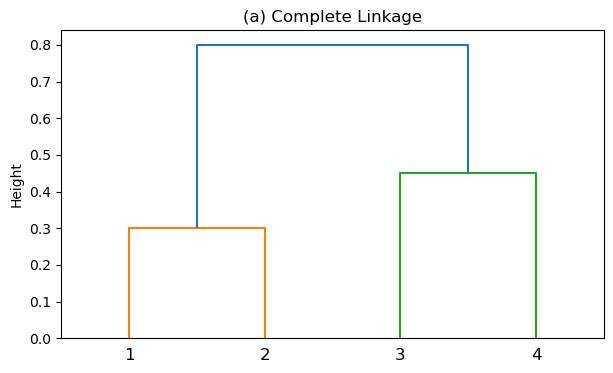

In [11]:
# (a) Complete Linkage
plt.figure(figsize=(7, 4))
dendrogram(Z_complete, labels=["1", "2", "3", "4"])
plt.title("(a) Complete Linkage")
plt.ylabel("Height")
plt.show()

### (b) Single Linkage

Single linkage defines the distance between two clusters as the minimum pairwise dissimilarity between their observations.

$$
d(A,B)=\min_{i\in A,\;j\in B}d(i,j)
$$

The hierarchical clustering proceeds as follows:

1. Merge observations 1 and 2 at height 0.30.
2. Merge cluster {1, 2} and observation 3 at height 0.40.
3. Merge cluster {1, 2, 3} and observation 4 at height 0.45.

The second and third merge heights are calculated as:

$$
d({1,2},{3})=\min(0.4,0.5)=0.40
$$

$$
d({1,2,3},{4})=\min(0.7,0.8,0.45)=0.45
$$

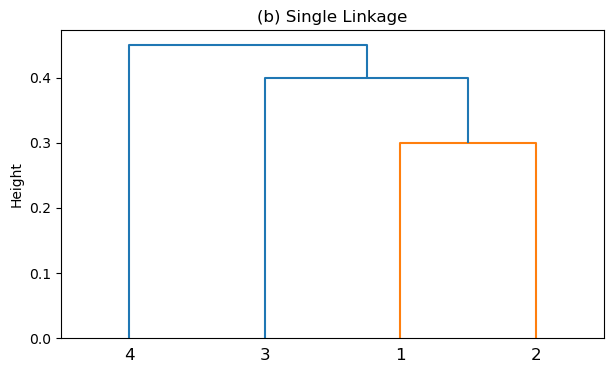

In [12]:
# (b) Single Linkage
plt.figure(figsize=(7, 4))
dendrogram(Z_single, labels=["1", "2", "3", "4"])
plt.title("(b) Single Linkage")
plt.ylabel("Height")
plt.show()

### (c) Complete Linkage — Two Clusters

Cutting the complete linkage dendrogram to obtain two clusters results in:

* Cluster 1: {1, 2}
* Cluster 2: {3, 4}

### (d) Single Linkage — Two Clusters

Cutting the single linkage dendrogram to obtain two clusters results in:

* Cluster 1: {1, 2, 3}
* Cluster 2: {4}

### (e) Equivalent Dendrogram

Swapping the left and right branches of a dendrogram does not change its hierarchical clustering structure.

For example, the original leaf order (1, 2, 3, 4) can be changed to (2, 1, 4, 3) while preserving the same cluster memberships and merge heights.

The resulting dendrogram is equivalent to the original complete linkage dendrogram because the clustering relationships remain unchanged.

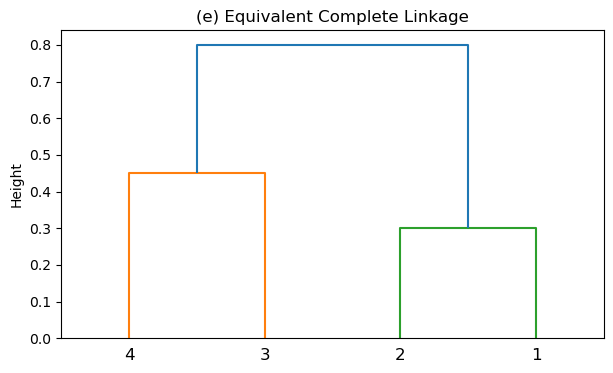

In [13]:
# (e) Equivalent Dendrogram
Z_equivalent = Z_complete.copy()
Z_equivalent[:, :2] = Z_equivalent[:, 1::-1]

plt.figure(figsize=(7, 4))
dendrogram(Z_equivalent, labels=["1", "2", "3", "4"])
plt.title("(e) Equivalent Complete Linkage")
plt.ylabel("Height")
plt.show()